# Modelo Dinámico del submarino: 6-DOF

In [1]:
# Windows 下让 Conda 环境的 DLL 可以被 NumPy、SciPy 等数值库找到。
# 这段只补充 PATH，不会安装或修改任何 Python 包。
import os
import sys
if sys.platform == "win32":
    conda_library_bin = os.path.normcase(os.path.abspath(os.path.join(sys.prefix, "Library", "bin")))
    path_entries = {os.path.normcase(os.path.abspath(path)) for path in os.environ.get("PATH", "").split(os.pathsep) if path}
    if os.path.isdir(conda_library_bin) and conda_library_bin not in path_entries:
        os.environ["PATH"] = conda_library_bin + os.pathsep + os.environ.get("PATH", "")
# 符号力学：定义参考坐标系、空间点、刚体和广义坐标。
from sympy.physics.mechanics import ReferenceFrame,Point,dynamicsymbols
from sympy.physics.mechanics import Point,RigidBody,inertia, KanesMethod
from sympy import latex,pprint,symbols,init_printing
from sympy.algebras.quaternion import Quaternion
from sympy.physics.mechanics import LagrangesMethod, Lagrangian
# 数值仿真与符号表达式数值化。
from scipy.integrate import odeint
from sympy import lambdify
# 绘图、动画和数组计算。
import matplotlib.pyplot as plt
from matplotlib import animation
import numpy as np
import sympy
# 项目自带的 3D ROV 可视化工具（位于 tools/vis.py）。
from tools.vis import Visualizer
%matplotlib inline
init_printing() # Para visualizar símbolos

In [2]:
# 把向量 expr 投影到 frame 的 x/y/z 轴，返回三个标量分量。
# simplify=True 时先化简分量，表达式更短但计算会稍慢。
def getComponents(expr,frame,simplify=True):
    if simplify:
        return [expr.dot(frame.x).simplify(),expr.dot(frame.y).simplify(),expr.dot(frame.z).simplify()]
    else:
        return [expr.dot(frame.x),expr.dot(frame.y),expr.dot(frame.z)]

In [3]:
# t 是符号时间变量；q_i(t) 等广义坐标会随时间变化。
t=symbols('t')
# ROV 的质量、三个主惯量和重力加速度。
[m,Ixx,Iyy,Izz,g]=symbols('m,Ixx,Iyy,Izz,g')
# 六个推进器相对于艇体参考点的位置 (x_i,y_i)，以及安装角 beta_i。
[x1,y1,x2,y2,x3,y3,x4,y4,x5,y5,x6,y6,beta1,beta2,beta3,beta4]=symbols('x1,y1,x2,y2,x3,y3,x4,y4,x5,y5,x6,y6,beta1,beta2,beta3,beta4')
# 六自由度广义坐标：q1/q2/q3 为位置，q4/q5/q6 为姿态角。
[q1,q2,q3,q4,q5,q6]=dynamicsymbols('q1 q2 q3 q4 q5 q6')
# 一阶和二阶时间导数，分别表示广义速度、广义加速度。
q1d,q2d,q3d,q4d,q5d,q6d=dynamicsymbols('q1 q2 q3 q4 q5 q6',1)
q1dd,q2dd,q3dd,q4dd,q5dd,q6dd=dynamicsymbols('q1 q2 q3 q4 q5 q6',2)

# N 是世界坐标系；A1/A2/A 逐次绕 z、y、x 轴转动，描述艇体姿态。
N=ReferenceFrame('N')
A1=N.orientnew('A1','Axis',(q4,N.z))
A2=A1.orientnew('A2','Axis',(q5,A1.y))
A=A2.orientnew('A','Axis',(q6,A2.x))
# B1--B4 为推进器安装方向；B5、B6 当前都按绕艇体 x 轴转 90 度定义。
B1=A.orientnew('B1','Axis',(-beta1,A.z))
B2=A.orientnew('B2','Axis',(beta2,A.z))
B3=A.orientnew('B3','Axis',(-beta3,A.z))
B4=A.orientnew('B4','Axis',(beta4,A.z))
B5=A.orientnew('B6','Axis',(np.deg2rad(90),A.x))
B6=A.orientnew('B6','Axis',(np.deg2rad(90),A.x))

# O 是世界原点，a 是艇体参考点；位置由前三个广义坐标给出。
O=Point('O')
a=O.locatenew('A',q1*N.x+q2*N.y+q3*N.z)
# 声明艇体相对世界坐标系的角速度，以及参考点的线速度。
A.set_ang_vel(A,q4d*N.z+q5d*A1.y+q6d*A2.x)
a.set_vel(N,q1d*N.x+q2d*N.y+q3d*N.z)
# 每个推进器的位置点 b_i 用艇体坐标系中的 (x_i,y_i) 定义。
b1=a.locatenew('b1',x1*A.x+y1*A.y)
b2=a.locatenew('b2',x2*A.x+y2*A.y)
b3=a.locatenew('b3',x3*A.x+y3*A.y)
b4=a.locatenew('b4',x4*A.x+y4*A.y)
b5=a.locatenew('b5',x5*A.x+y5*A.y)
b6=a.locatenew('b6',x6*A.x+y6*A.y)

In [4]:
# 调试/查看用：显示 SymPy 已登记的各坐标系角速度关系。
A._ang_vel_dict

{A2: Derivative(q6(t), t)*A2.x,
 B1: 0,
 B2: 0,
 B3: 0,
 B4: 0,
 B6: 0,
 B6: 0,
 A: - Derivative(q4(t), t)*N.z - Derivative(q5(t), t)*A1.y - Derivative(q6(t), t)*A2.x}

In [5]:
# f_i 表示第 i 个推进器的推力大小（仿真时再赋具体数值）。
[f1,f2,f3,f4,f5,f6]=symbols('f1,f2,f3,f4,f5,f6')
# 推力沿推进器坐标系的 y 轴；投影到世界系 N 后得到力向量 F_i。
F1=getComponents(f1*B1.y,N)[0]*N.x+getComponents(f1*B1.y,N)[1]*N.y+getComponents(f1*B1.y,N)[2]*N.z
F2=getComponents(f2*B2.y,N)[0]*N.x+getComponents(f2*B2.y,N)[1]*N.y+getComponents(f2*B2.y,N)[2]*N.z
F3=getComponents(f3*B3.y,N)[0]*N.x+getComponents(f3*B3.y,N)[1]*N.y+getComponents(f3*B3.y,N)[2]*N.z
F4=getComponents(f4*B4.y,N)[0]*N.x+getComponents(f4*B4.y,N)[1]*N.y+getComponents(f4*B4.y,N)[2]*N.z
F5=getComponents(f5*B5.y,N)[0]*N.x+getComponents(f5*B5.y,N)[1]*N.y+getComponents(f5*B5.y,N)[2]*N.z
F6=getComponents(f6*B6.y,N)[0]*N.x+getComponents(f6*B6.y,N)[1]*N.y+getComponents(f6*B6.y,N)[2]*N.z

In [6]:
# 用艇体坐标系 A 定义主惯性矩阵，并在参考点 a 建立刚体模型。
inertia_sub=inertia(A,Ixx,Iyy,Izz)
sub = RigidBody('S',a,A,m,(inertia_sub,a))

In [7]:
# 重力势能；正负号取决于模型对 q3 和重力方向的坐标约定。
sub.potential_energy = -m*g*q3
sub.potential_energy

In [8]:
# 显示刚体惯性张量，检查三个主惯量是否正确登记。
inertia_sub

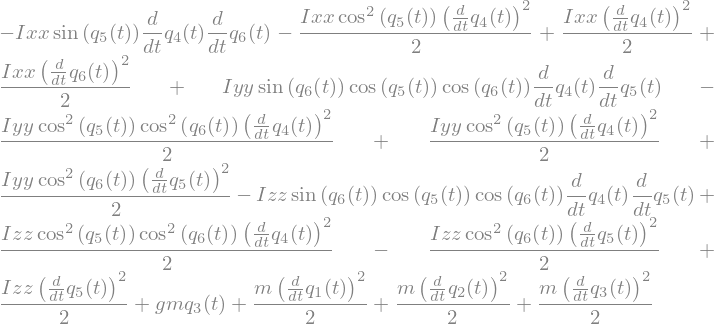

In [9]:
# 平动速度向量 v；角速度按三个转动自由度定义，并表达在世界系 N 中。
vel = q1d*N.x+q2d*N.y+q3d*N.z
ang_vel = (q4d*N.z+q5d*A1.y+q6d*A2.x).express(N)
# 总动能 = 平动动能 + 转动动能；惯性张量先转换到 N 坐标系。
T = sympy.simplify(sympy.Rational(1/2)*m*vel.dot(vel) + sympy.Rational(1/2)*ang_vel.dot(inertia_sub.express(N).dot(ang_vel)))
# 重力势能及拉格朗日函数 L=T-V。
V = -m*g*q3
L = T - V
L


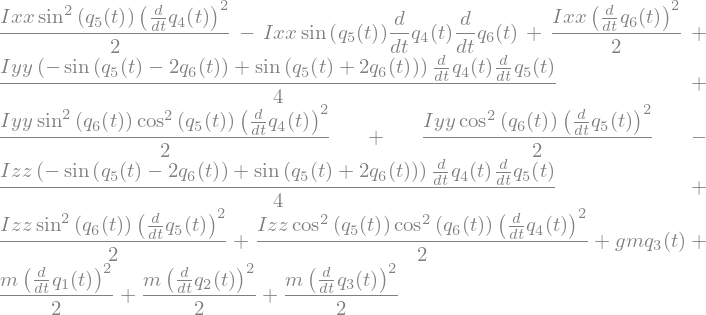

In [10]:
# 从刚体 sub 自动计算拉格朗日函数 L=T-V（与上一单元手动构造的 L 对应）。
L=sympy.simplify(Lagrangian(N,sub))
L

In [11]:
# 将每个推进器的作用点和力向量配对，作为外力输入拉格朗日方程。
ftuples = [(b1,F1),(b2,F2),(b3,F3),(b4,F4),(b5,F5),(b6,F6)]
# 建立六个广义坐标的拉格朗日方程，并展开得到运动方程。
lm = LagrangesMethod(L,[q1,q2,q3,q4,q5,q6],ftuples,frame=N)
eqs = lm.form_lagranges_equations()

In [12]:
# 对方程中的三角函数和代数项做符号化简。
eqs.simplify()



In [13]:
# 显示推导出的广义运动方程，便于检查符号结果。
eqs

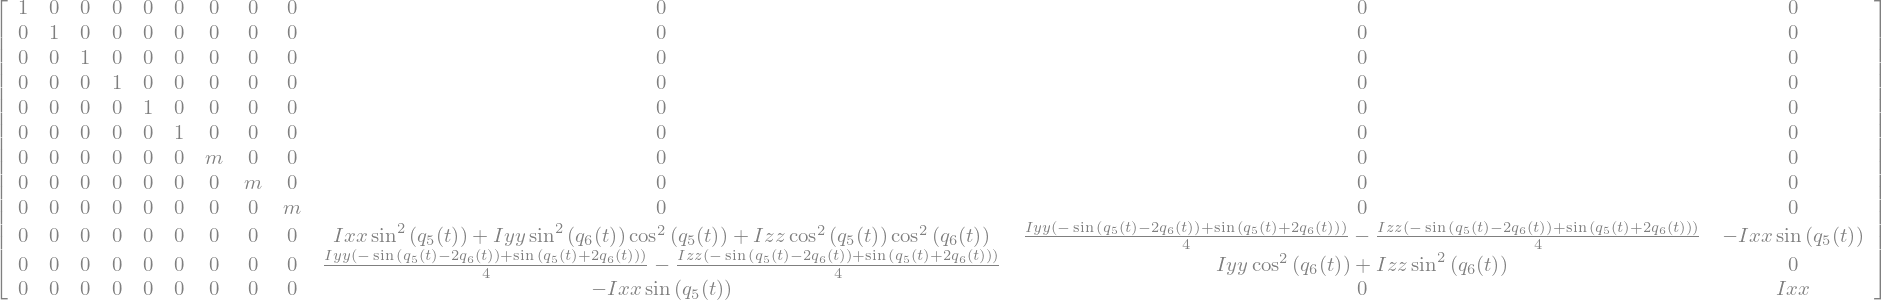

In [14]:
# 显示完整质量矩阵；该矩阵用于 M(q)*qdd = forcing。
lm.mass_matrix_full



In [15]:
# 显示与质量矩阵对应的广义力项（含速度、重力和推进器作用）。
sympy.simplify(lm.forcing_full)

In [16]:
# 不在这里调用 lm.rhs()：它会符号求解质量矩阵，模型表达式较大时可能非常耗内存。
# 仿真单元会先代入数值参数，再逐步数值求解质量矩阵。

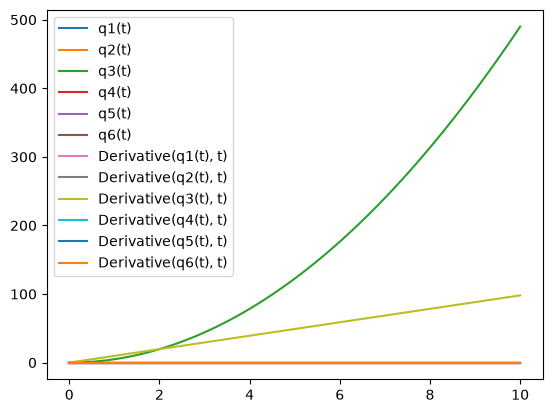

In [17]:
# -------- 1. 设置初始状态和模型参数 --------
# 最终目标：对 6 自由度模型做数值仿真，并绘制运动曲线。
# 状态顺序固定为 [q1..q6, q1d..q6d]，即六个坐标后接六个速度。
# de dinamica directa utilizando un integrador de ecuaciones diferenciales
# de primer orden.

# Defina las condiciones iniciales del sistema
x0=[0,0,0,0,0,0,0,0,0,0,0,0]
# 为符号模型中的质量、惯量、推力、安装位置、安装角和重力赋数值。
# Parameters used by the numerical model
parameters={f1:0,f2:0,f3:0,f4:0,f5:0,f6:0,m:4,Ixx:1064.294e-4,Iyy:1577.872e-4,Izz:951.955e-4,
            x1:-0.20,x2:0.20,x3:0.20,x4:-0.20,x5:-0.4,x6:0.4,
            y1:0.20,y2:0.20,y3:-0.20,y4:-0.20,y5:0,y6:0,
            beta1:np.deg2rad(45),beta2:np.deg2rad(45),beta3:np.deg2rad(45),
            beta4:np.deg2rad(45),g:9.8}

# 修改 f1...f6 可以模拟不同推进器推力；这里 f5/f6 设置为很小的非零值。
# la simulación
parameters[f1]=0#-0.1*q1d-0.1*(q1-0.5)
parameters[f2]=0#-0.1*q2d-0.1*(q2-0.5)
parameters[f3]=0
parameters[f4]=0
parameters[f5]=0.000001
parameters[f6]=0.000001


# 生成 0 到 10 秒的 100 个积分采样时刻。
t=np.linspace(0,10,100)
# 将广义坐标和速度作为数值函数的输入变量。
state_vars=[q1,q2,q3,q4,q5,q6,q1d,q2d,q3d,q4d,q5d,q6d]
# 先把常量代入，再将符号质量矩阵 M(q) 和广义力向量 F(q,qdot) 编译为 NumPy 函数。
# 运动方程为 M(q)*qdd=F；不预先对符号矩阵求逆，节省符号计算资源。
mass_fun=lambdify(state_vars,lm.mass_matrix.subs(parameters),modules="numpy")
forcing_fun=lambdify(state_vars,lm.forcing.subs(parameters),modules="numpy")
# odeint 每一步都会调用此函数，要求返回整个 12 维状态的时间导数。
def ode_fun(x,t):
    # 当前状态包含六个位置/姿态坐标及其六个广义速度。
    state=tuple(x)
    mass=np.asarray(mass_fun(*state),dtype=float)
    forcing=np.asarray(forcing_fun(*state),dtype=float).reshape(6)
    # 数值求解 M*qdd=F 得到六个广义加速度（比符号求逆更稳健）。
    acceleration=np.linalg.solve(mass,forcing)
    # 坐标的导数就是速度；速度的导数就是加速度。
    return np.concatenate((np.asarray(x[6:]),acceleration))
# 积分状态方程；结果 x 的每一行对应一个时刻的 12 维状态。
x=odeint(ode_fun,x0,t)

# 绘制六个广义坐标和六个广义速度随时间的变化曲线。
plt.figure()
plt.plot(t,x)
plt.legend([q1,q2,q3,q4,q5,q6,q1d,q2d,q3d,q4d,q5d,q6d])
plt.show()

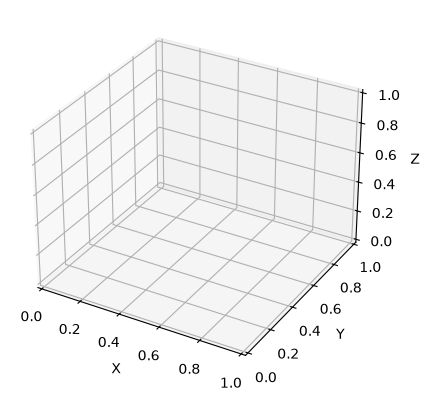

MovieWriter ffmpeg unavailable; using Pillow instead.


In [18]:
# -------- 三维可视化与动画 --------
# 创建 3D 画布，把艇体 STL 网格和艇体坐标系添加到图中。
vis=Visualizer(N,O)
vis.add(A,a,shape='sub.stl')
vis.add(A,a,frame_scale=100)


# 用初始姿态更新图形并保存静态图；当前 x0 全为 0，所以各坐标均为零。
vis.plot({q1:x0[0],q2:x0[0],q3:x0[0],q4:x0[0],q5:x0[0],q6:x0[0]})
vis.fig.savefig('plot1.png')

# 动画每一帧调用 update：取第 i 个时刻的前六个状态作为位置和姿态。
def update(i,data):
    vis.plot({q1:data[i,0],q2:data[i,1],q3:data[i,2],q4:data[i,3],q5:data[i,4],q6:data[i,5]})
    
# 建立逐帧动画；frames 是仿真采样点数，data=x 传给 update。
ani = animation.FuncAnimation(vis.fig, update, x.shape[0], fargs=(x,), interval=10/x.shape[0], blit=False)
# 将动画导出为 GIF，fps 控制每秒播放帧数。
ani.save('animation1.gif',fps=20)